# Twitter Sentiment and Socio-Economic Inequalities in U.S. Neighbourhoods

**How does your environment affect your digital expression?**

**Stats.json - Top 10 Cities**

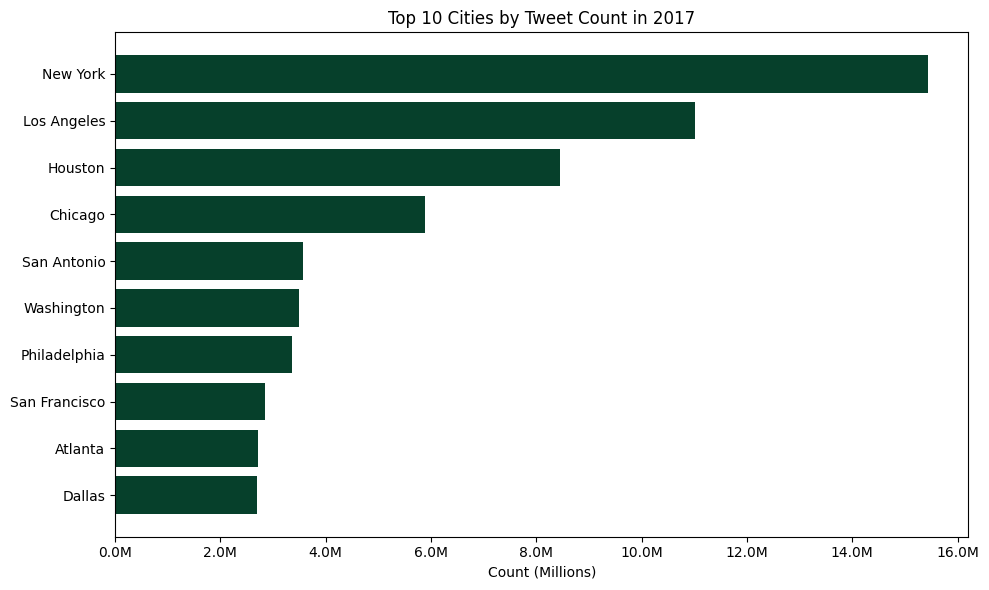

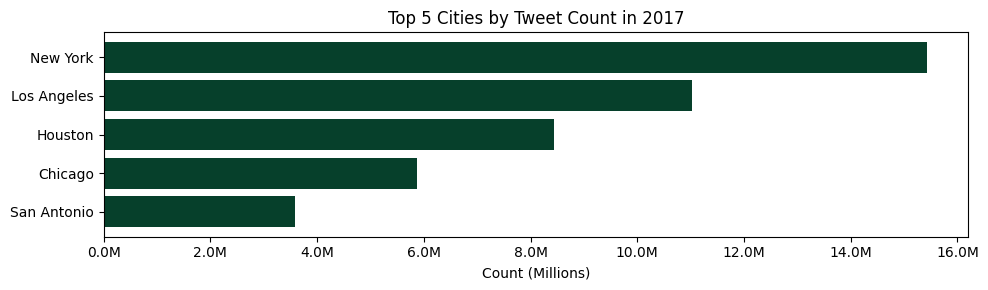

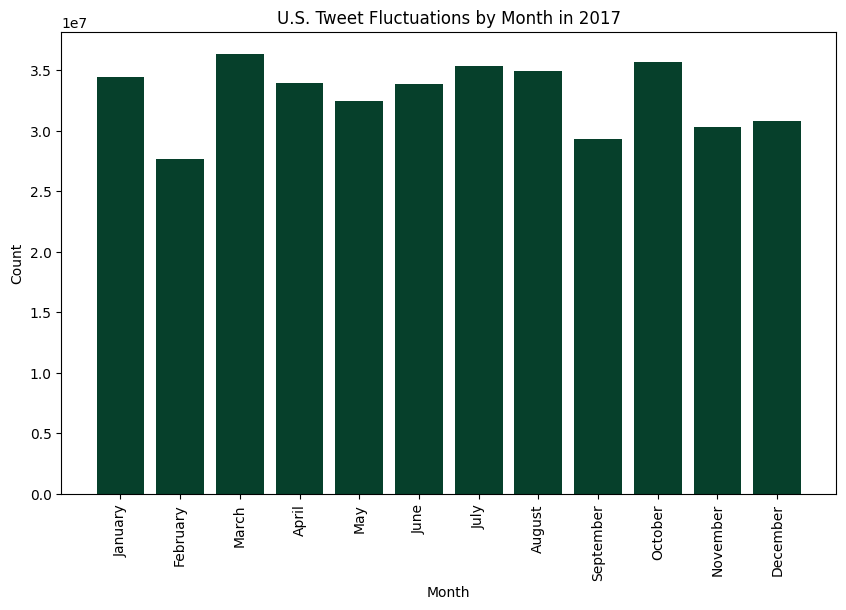

In [71]:
import json
import matplotlib.pyplot as plt

with open("../Stats.json", "r", encoding="utf-8") as f:
    stats = json.load(f)

# ---- Whole Year Data ----

# Sort cities by count and take top 10.
top10 = sorted(
    stats['cities'].items(),
    key=lambda x : x[1],
    reverse=True
)[:10]

# Seperate counts and cities from each tuple.
cities = [c for c, _ in top10]
counts = [n for _, n in top10]

# Plot to show the top 10 cities by tweet count over the entire year.

plt.figure(figsize=(10, 6))
plt.barh(cities, counts, color='#06402B')
plt.gca().invert_yaxis()

plt.xlabel("Count (Millions)")
plt.title("Top 10 Cities by Tweet Count in 2017")

import matplotlib.ticker as ticker
plt.gca().xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1000000:.1f}M')
)

plt.tight_layout()
plt.savefig("../Figures/Tweet_Count_Top10.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot for the top 5

plt.figure(figsize=(10, 3))
plt.barh(cities[:5], counts[:5], color='#06402B')
plt.gca().invert_yaxis()

plt.xlabel("Count (Millions)")
plt.title("Top 5 Cities by Tweet Count in 2017")

import matplotlib.ticker as ticker
plt.gca().xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1000000:.1f}M')
)

plt.tight_layout()
plt.savefig("../Figures/Tweet_Count_Top5.png", dpi=300, bbox_inches="tight")
plt.show()

# ---- Month by Month Data ----

month_key = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
tweet_count = []

f = open("../General_Stats.txt", 'w')
f.write(f"Total Count: {stats['count']:,}\n\nDifferent Users: {stats['different_users']:,}\n\n")

f.write("Overall Top 10 Cities:\n\n")
for city, count in top10:
    f.write(f"{city}: {count:,}\n")


for month, data in stats["monthly"].items():

    month_name = month_key[int(month) - 1]

    tweet_count.append(data['count'])
    
    f.write(f"\n--- {month_name} ---\n\n")

    f.write(f"Total Tweets: {data['count']:,}\n\n")
    f.write(f"Total Different Users: {data['different_users']:,}\n")

    f.write(f"Top 10 Cities in {month_name}\n\n")
    

    m_top10 = sorted(
        data['cities'].items(),
        key=lambda x: x[1],
        reverse=True
    )[:10]


    for city, count in m_top10:
        f.write(f"{city}: {count:,}\n")

f.close()

plt.figure(figsize=(10,6))
plt.bar(month_key, tweet_count, color='#06402B')

plt.xlabel("Month")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.title("U.S. Tweet Fluctuations by Month in 2017")
plt.savefig("../Figures/Tweet_Count_Months.png", dpi=300, bbox_inches="tight")
plt.show()



**Bounding Box Sizes**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import json
from pathlib import Path
from Archive_Code.AnalysisTools import bbox_area_km2

city = "New York"
folder_path = Path(f'../CityTweets/{city}/')

bbox_areas = []

for file_path in folder_path.glob('*.jsonl'):
    with file_path.open("r", encoding="utf-8") as f:
        for line in f:
            try:
                tweet = json.loads(line)
                bbox = tweet.get('bounding_box')
                area = bbox_area_km2(bbox)
                if area is not None:
                    bbox_areas.append(area)
            except json.JSONDecodeError:
                continue

print(f"Total bounding boxes read: {len(bbox_areas)}")


Total bounding boxes read: 15434377


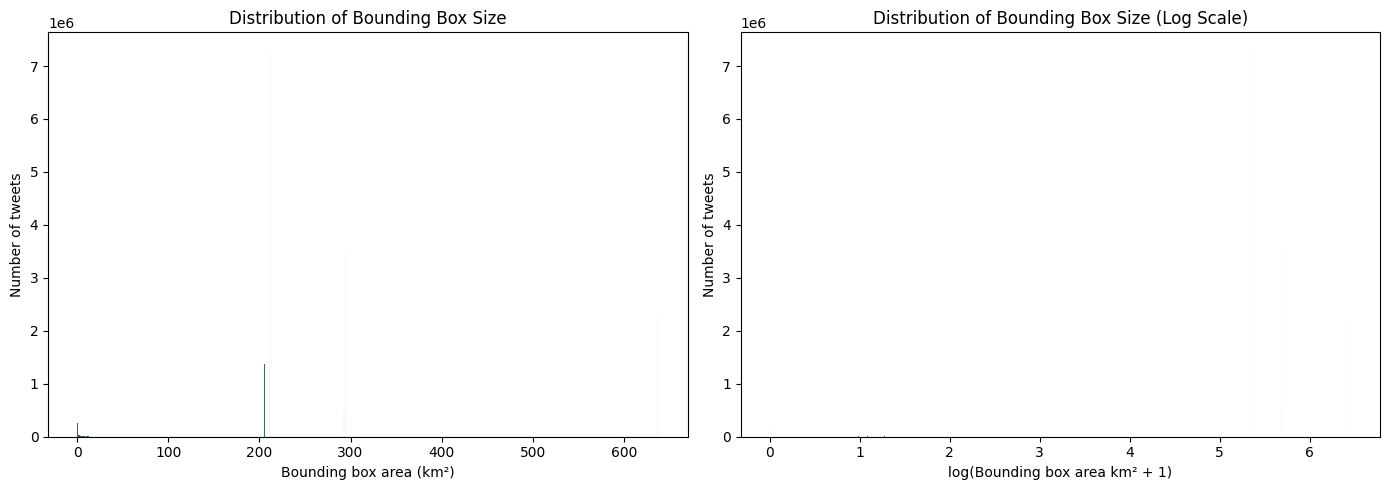

Median area: 211.1596 km²
Mean area:   287.9170 km²
Max area:    638.0271 km²
Min area:    0.0000 km²


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(bbox_areas, fill=True, color='#06402B', ax=axes[0])
axes[0].set_xlabel("Bounding box area (km²)")
axes[0].set_ylabel("Number of tweets")
axes[0].set_title("Distribution of Bounding Box Size")

sns.histplot(np.log1p(bbox_areas), fill=True, color='#06402B', ax=axes[1])
axes[1].set_xlabel("log(Bounding box area km² + 1)")
axes[1].set_ylabel("Number of tweets")
axes[1].set_title("Distribution of Bounding Box Size (Log Scale)")

plt.tight_layout()
plt.show()
print(f"Median area: {np.median(bbox_areas):.4f} km²")
print(f"Mean area:   {np.mean(bbox_areas):.4f} km²")
print(f"Max area:    {np.max(bbox_areas):.4f} km²")
print(f"Min area:    {np.min(bbox_areas):.4f} km²")

**City By City**

How large are Census Tracts:

Mean: 0.4784km², Median: 0.3098km², Std Dev: 0.6469km², +1 Std Dev: 1.1253km²


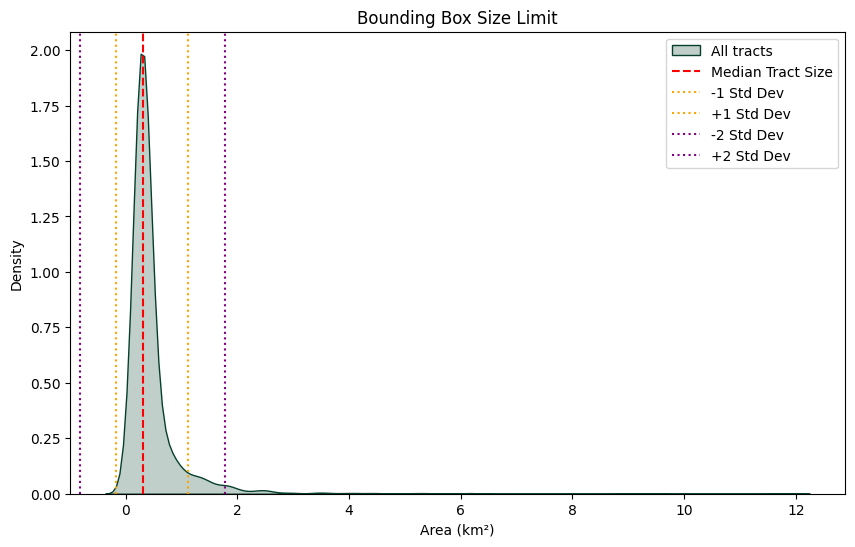

In [9]:
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

shapefile_path = "Utilities/Shapefiles/New York Tracts/tl_2017_36_tract.shp"
tracts = gpd.read_file(shapefile_path)

city_boundaries = gpd.read_file("Utilities/Shapefiles/CityBoundaries.shp")
new_york = city_boundaries[city_boundaries["NAME"] == "New York"]

if tracts.crs.is_geographic:
    tracts = tracts.to_crs(epsg=3857)

tracts = gpd.sjoin(tracts, new_york, how="inner", predicate="within")

tracts['area_m2'] = tracts.geometry.area
tracts['area_km2'] = tracts['area_m2'] / 1000000

median_area = tracts['area_km2'].median()
mean_area = tracts['area_km2'].mean()
std_area = tracts['area_km2'].std()

print(f"Mean: {mean_area:.4f}km², Median: {median_area:.4f}km², Std Dev: {std_area:.4f}km², +1 Std Dev: {mean_area + std_area:.4f}km²")

# Median Histogram with std dev markers
plt.figure(figsize=(10, 6))
sns.kdeplot(tracts['area_km2'], fill=True, color='#06402B', label='All tracts')
plt.axvline(median_area, color='red', linestyle='--', label='Median Tract Size')
plt.axvline(mean_area - std_area, color='orange', linestyle=':', label='-1 Std Dev')
plt.axvline(mean_area + std_area, color='orange', linestyle=':', label='+1 Std Dev')
plt.axvline(mean_area - 2 * std_area, color='purple', linestyle=':', label='-2 Std Dev')
plt.axvline(mean_area + 2 * std_area, color='purple', linestyle=':', label='+2 Std Dev')
plt.xlabel('Area (km²)')
plt.ylabel('Density')
plt.title('Bounding Box Size Limit')
plt.legend()
plt.show()

New York

In [ ]:
from Archive_Code.AnalysisTools import map_city_tweets

tracts_info = map_city_tweets(
        city="New York",
        shapefile="Utilities/Shapefiles/New York Tracts/tl_2017_36_tract.shp",
        outfile="../CityMaps/NYC_Tweet_Map.html",
        map_start=[40.7128, -74.0060]
    )


h:\Twitter Sentiment\Code\AnalysisTools.py:36: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  tracts['area_km2'] = tracts.geometry.area / 1000000


Reading tweets...
Valid tweet points: 15434377
Running spatial join...
Counting tweets per tract...
Creating map...
Map saved to ../CityMaps/NYC_Tweet_Map.html
Unused tweets skipped: 0


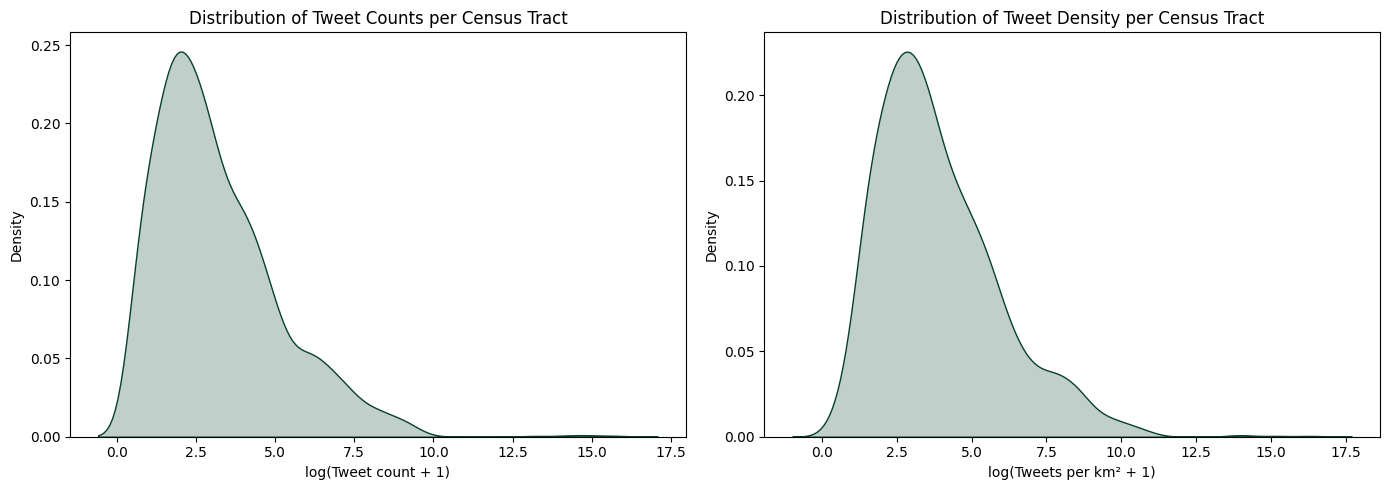

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

tracts_info = tracts_info[tracts_info["tweet_count"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(np.log1p(tracts_info["tweet_count"]), fill=True, color='#06402B', ax=axes[0])
axes[0].set_xlabel("log(Tweet count + 1)")
axes[0].set_ylabel("Density")
axes[0].set_title("Distribution of Tweet Counts per Census Tract")

sns.kdeplot(np.log1p(tracts_info["tweet_density"]), fill=True, color='#06402B', ax=axes[1])
axes[1].set_xlabel("log(Tweets per km² + 1)")
axes[1].set_ylabel("Density")
axes[1].set_title("Distribution of Tweet Density per Census Tract")

plt.tight_layout()
plt.show()

In [4]:
tracts_info.head()

,GEOID,tweet_count,tweet_density
0,36081003400,6,16.106995
1,36081003900,3,11.698458
3,36081003700,69,98.561609
4,36081003800,5,16.299590
5,36081004001,2,6.592112


### Census Data

*Socioeconomic Status and Demographic Characteristics of Census Tracts (2010 Census), United States, 2008-2017 Data*

*https://www.icpsr.umich.edu/sites/nanda/view/studies/38528/datasets/2*

In [5]:
import pandas as pd
import geopandas as gpd

census = pd.read_csv("Utilities/ICPSR-CENSUS.tsv", delimiter="\t")

census.tail()
# Tract ID is TRACT_FIPS10

C:\Users\tmcav\AppData\Local\Temp\ipykernel_268\1212052970.py:4: DtypeWarning: Columns (0: ALAND10, 1: TOTPOP13_17) have mixed types. Specify dtype option on import or set low_memory=False.
  census = pd.read_csv("Utilities/ICPSR-CENSUS.tsv", delimiter="\t")


,TRACT_FIPS10,ALAND10,TOTPOP08_12,TOTPOP13_17,POPDEN08_12,POPDEN13_17,PHISPANIC08_12,PHISPANIC13_17,PNHWHITE08_12,PNHWHITE13_17,...,POWNOC08_12,POWNOC13_17,DISADVANTAGE08_12,DISADVANTAGE13_17,DISADVANTAGE2_08_12,DISADVANTAGE2_13_17,AFFLUENCE08_12,AFFLUENCE13_17,ETHNICIMMIGRANT08_12,ETHNICIMMIGRANT13_17
73076,56043000200,2231.885009766,3154,3202,1.4131552,1.43466175,.0913126170635,.0908806994557,.8620799183846,.8725796341896,...,.7836257219315,.8135095238686,.0416450090706,.0512379929423,.052056260407,.0620955862105,.3465714752674,.3610932230949,.0646797716618,.0501249209046
73077,56043000301,.769579232,2965,2446,3850.64941407,3178.36010742,.1682967990637,.1725265681744,.8290050625801,.7935404777527,...,.5780757069588,.6993810534477,.0978163480759,.0788072422147,.1222704350948,.0985090509057,.2317242175341,.2647680640221,.0996627360582,.0878986120224
73078,56043000302,5.894155979,2306,2605,391.24533081,441.9631958,.1591500490904,.1773512512445,.8117952942848,.7861804366112,...,.7340862154961,.7602808475494,.039271555841,.066191829741,.0458370633423,.0827397853136,.3846621513367,.2845707833767,.098872512579,.1184261068702
73079,56045951100,2355.307617188,3128,3329,1.32806408,1.41340351,.0262148343027,.0297386609018,.9590792655945,.8942625522614,...,.8083881735802,.7892562150955,.0437369532883,.0416895337403,.0543514974415,.0496336966753,.2942948043346,.3658003211021,.014066496864,.0330429561436
73080,56045951300,42.78087616,4024,3788,94.06044769,88.54423523,.0350397601724,.0010559662478,.9155069589615,.9358500242233,...,.7732491493225,.7462427616119,.0673963874578,.0694403350353,.0842454880476,.0868004187942,.3050404787064,.3460934460163,.0233598407358,.0204593446106


In [6]:
tracts = gpd.read_file("Utilities/Shapefiles/New York Tracts/tl_2017_36_tract.shp")
# Tract Code = GEOID

# Make codes are of the same datatype.
census['TRACT_FIPS10'] = census['TRACT_FIPS10'].astype(str)
tracts['GEOID'] = tracts['GEOID'].astype(str)

# Pad in case of lost leading zeros.
census['TRACT_FIPS10'] = census['TRACT_FIPS10'].str.zfill(11)
tracts['GEOID'] = tracts['GEOID'].str.zfill(11)

valid_tracts = tracts['GEOID'].unique()
census_filtered = census[census['TRACT_FIPS10'].isin(valid_tracts)].copy()

pin1b_13_17 - Proportion of families with income less than 15k

pin2b_13_17 - Proportion of families with income 15k-30k

pin3b_13_17 - Proportion of families with income 30k-50k

pin4b_13_17 - Proportion of families with income 50k-100k

pin5b_13_17 - Proportion of families with income >100k

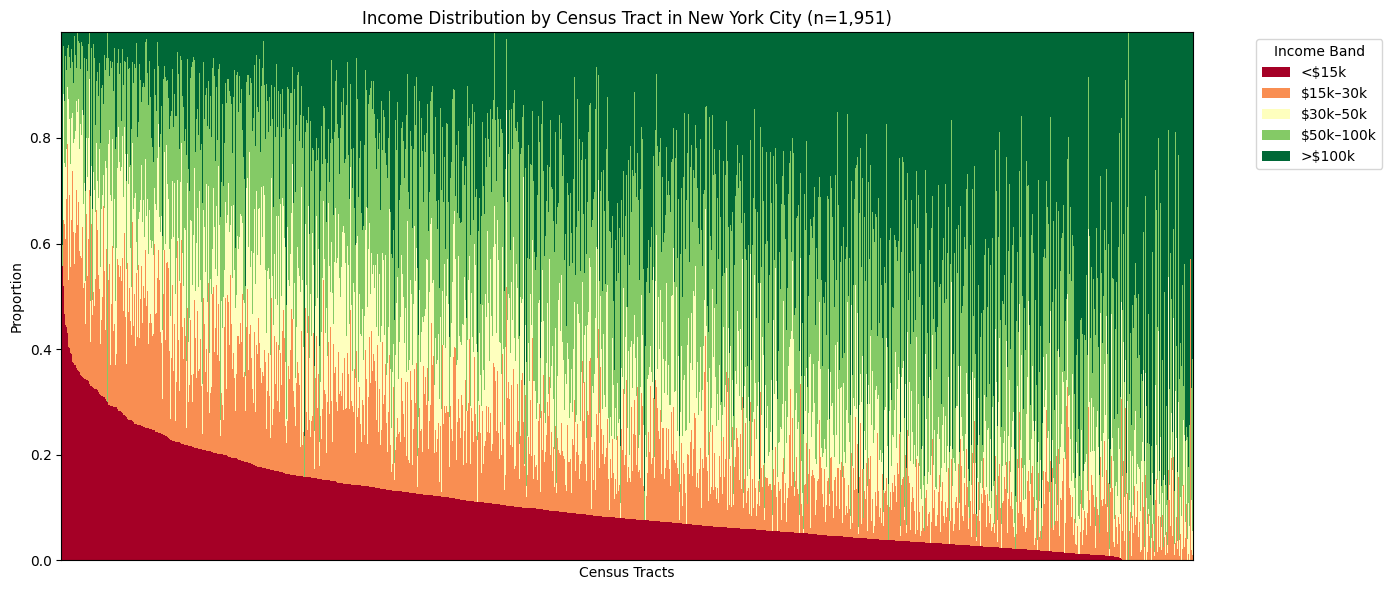

In [7]:
import matplotlib.pyplot as plt

cols = ['PIN1B_13_17', 'PIN2B_13_17', 'PIN3B_13_17', 'PIN4B_13_17', 'PIN5B_13_17']
labels = ['<$15k', '$15k–30k', '$30k–50k', '$50k–100k', '>$100k']

census_filtered = census_filtered[census_filtered['TRACT_FIPS10'].isin(tracts_info['GEOID'])]

census_filtered[cols] = census_filtered[cols].apply(pd.to_numeric, errors='coerce')
census_filtered = census_filtered.sort_values('PIN1B_13_17', ascending=False)

census_filtered_clean = census_filtered.dropna(subset=cols)

ax = census_filtered_clean.sort_values('PIN1B_13_17', ascending=False)[cols]\
    .rename(columns=dict(zip(cols, labels))).plot(
        kind='bar', stacked=True, figsize=(14, 6), colormap='RdYlGn', width=1.0
    )

ax.set_xticks([])
ax.set_xlabel('Census Tracts')
ax.set_ylabel('Proportion')
ax.set_title('Income Distribution by Census Tract in New York City (n={:,})'.format(len(census_filtered_clean)))
ax.legend(title='Income Band', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

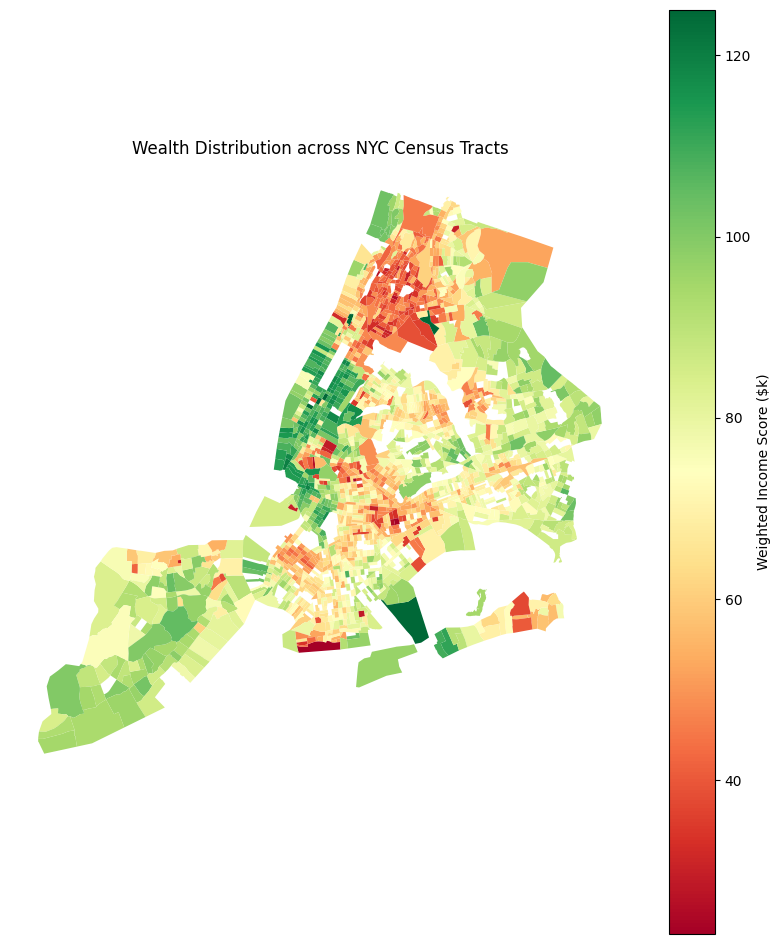

In [8]:
import geopandas as gpd

midpoints = [7.5, 22.5, 40, 75, 125]

census_filtered_clean['INCOME_SCORE'] = sum(
    census_filtered_clean[col] * mid for col, mid in zip(cols, midpoints)
)

gdf = gpd.read_file("Utilities/Shapefiles/New York Tracts/tl_2017_36_tract.shp")  
gdf = gdf.merge(census_filtered_clean[['TRACT_FIPS10', 'INCOME_SCORE']], 
                left_on='GEOID', right_on='TRACT_FIPS10')

gdf.plot(
    column='INCOME_SCORE',
    cmap='RdYlGn',
    legend=True,
    legend_kwds={'label': 'Weighted Income Score ($k)'},
    figsize=(10, 12)
)
plt.title('Wealth Distribution across NYC Census Tracts')
plt.axis('off')
plt.savefig("../Figures/Wealth_Distribution.png", dpi=150)
plt.show()

p18yr_13_17 - Proportion of population younger than 18 years old.
p18_2913_17 - Proportion of population 18-29 years old.
p30_3913_17 - Proportion of population 30-39 years old.
p40_4913_17 - Proportion of population 40-49 years old.
p50_6913_17 - Proportion of population 50-69 years old.
pge7013_17 - Proportion of population 70+ years old.

In [9]:
age_cols = ['P18_2913_17', 'P30_3913_17', 'P40_4913_17', 'P50_6913_17', 'PGE7013_17']
age_labels = ['18–29', '30–39', '40–49', '50–69', '70+']

gdf = gdf.merge(census_filtered_clean[['TRACT_FIPS10'] + age_cols],
                left_on='GEOID', right_on='TRACT_FIPS10', how='left')



#### Age Distribution Maps

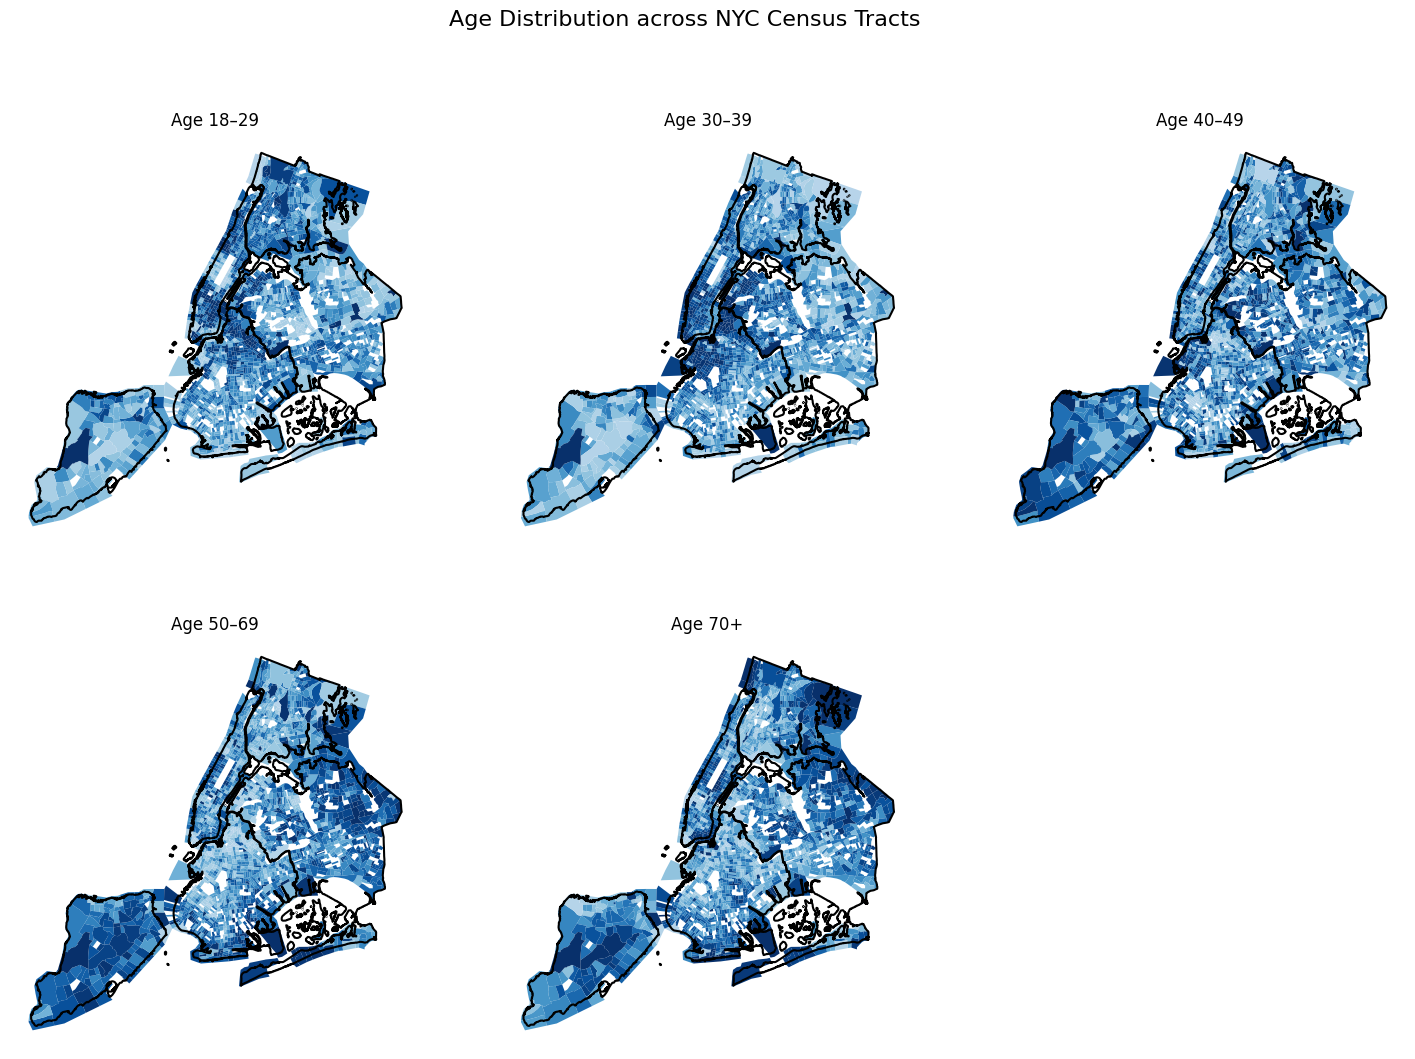

In [10]:
from matplotlib.colors import LinearSegmentedColormap

boroughs = gpd.read_file("Utilities/Boroughs.geojson")

blues_dark = plt.cm.Blues(np.linspace(0.3, 1.0, 256))
custom = LinearSegmentedColormap.from_list('custom', blues_dark)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, col, label in zip(axes.flatten(), age_cols, age_labels):
    gdf.plot(column=col, cmap=custom, legend=False, ax=ax)
    ax.set_title(f'Age {label}')
    ax.axis('off')
    boroughs.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1.5)

axes.flatten()[-1].set_visible(False)

plt.suptitle('Age Distribution across NYC Census Tracts', fontsize=16)
plt.savefig("../Figures/Age_Distributions.png", dpi=150)
plt.show()

#### Dominant Ages

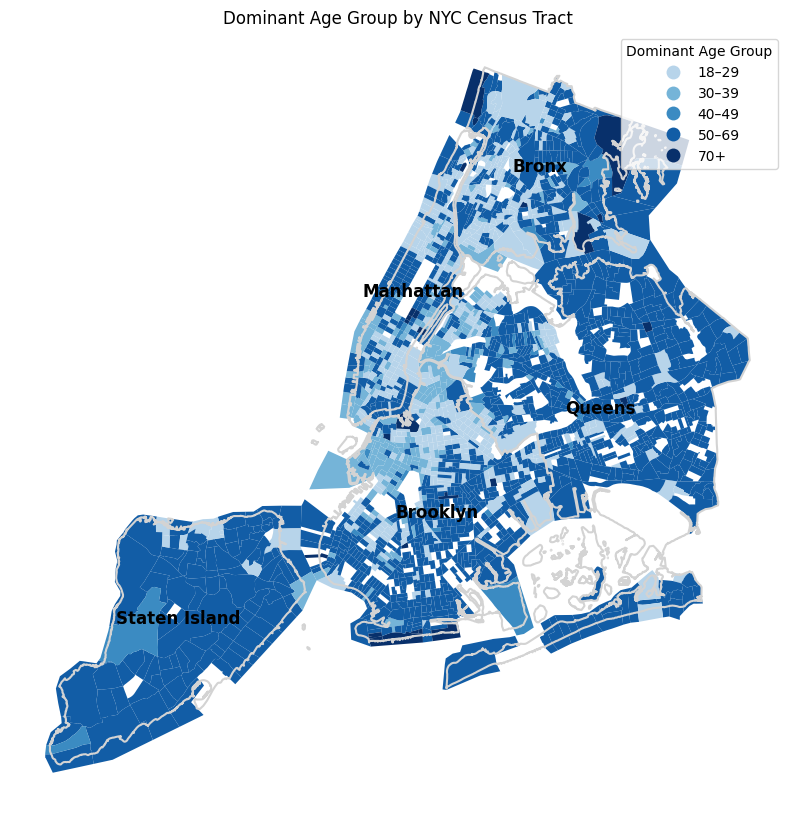

In [11]:


gdf['dominant_age'] = gdf[age_cols].idxmax(axis=1).map(dict(zip(age_cols, age_labels)))

ax = gdf.plot(column='dominant_age', cmap=custom, legend=True, figsize=(10, 12),
         legend_kwds={'title': 'Dominant Age Group'})
plt.title('Dominant Age Group by NYC Census Tract')
plt.axis('off')

boroughs.plot(ax=ax, facecolor='none', edgecolor='lightgray', linewidth=1.5)

for _, row in boroughs.iterrows():
    centroid = row.geometry.centroid
    plt.annotate(row['boroname'], xy=(centroid.x, centroid.y), ha='center', fontsize='12', fontweight='bold', color='black')

plt.savefig("../Figures/Dominant_Age.png", dpi=150)
plt.show()

## Sentiment Information

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import os

from Archive_Code.AnalysisTools import process_tweet_folder

CHOSEN_CITY = "New York"
CITY_LOCS = {
    "New York": [40.75, -73.97]
}

tracts = gpd.read_file(f"Utilities/Shapefiles/{CHOSEN_CITY} Tracts/tl_2017_36_tract.shp")
tracts = tracts.to_crs("EPSG:4326")
tracts.head()



,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,36,093,033102,36093033102,331.02,Census Tract 331.02,G5020,S,183329957,3232878,+42.7780137,-074.1727137,"POLYGON ((-74.30655 42.75064, -74.30624 42.751..."
1,36,093,020102,36093020102,201.02,Census Tract 201.02,G5020,S,854904,0,+42.8295375,-073.9161408,"POLYGON ((-73.92513 42.82029, -73.9244 42.8214..."
2,36,093,032504,36093032504,325.04,Census Tract 325.04,G5020,S,65998560,1265253,+42.9010539,-074.0288936,"POLYGON ((-74.09298 42.95587, -74.08805 42.955..."
3,36,081,003400,36081003400,34,Census Tract 34,G5020,S,213987,0,+40.6847731,-073.8581871,"POLYGON ((-73.8663 40.68319, -73.86549 40.6834..."
4,36,081,003900,36081003900,39,Census Tract 39,G5020,S,146970,0,+40.7627994,-073.9409316,"POLYGON ((-73.9433 40.76066, -73.94247 40.7619..."


In [13]:
if os.path.exists(f"../Pickles/{CHOSEN_CITY}.pkl"):
    # Load Pickle
    tweet_data = pd.read_pickle(f"../Pickles/{CHOSEN_CITY}.pkl")

else:
    tweet_data = process_tweet_folder(f"../CityTweets/{CHOSEN_CITY}/", tracts)
    # Avoid having to run this every time the kernel restarts.
    tweet_data.to_pickle(f"../Pickles/{CHOSEN_CITY}.pkl")

tweet_data.head()

,GEOID,date,mean_sentiment,tweet_count
0,36005002400,2017-01-01,0.480713,1
1,36005004100,2017-01-01,0.513672,1
2,36005006000,2017-01-01,0.540690,3
3,36005006300,2017-01-01,0.557210,3
4,36005007000,2017-01-01,0.507812,1


In [ ]:
from Archive_Code.AnalysisTools import compute_sentiment_change
tweet_data = compute_sentiment_change(tweet_data)
tweet_data.head()

,GEOID,date,mean_sentiment,tweet_count,sentiment_change
0,36005000100,2017-01-19,0.513672,1,NaN
0,36005000100,2017-02-26,0.498047,6,-0.015625
0,36005000100,2017-03-04,0.748291,2,0.250244
0,36005000100,2017-03-06,0.488525,1,-0.259766
0,36005000100,2017-03-20,0.511230,1,0.022705


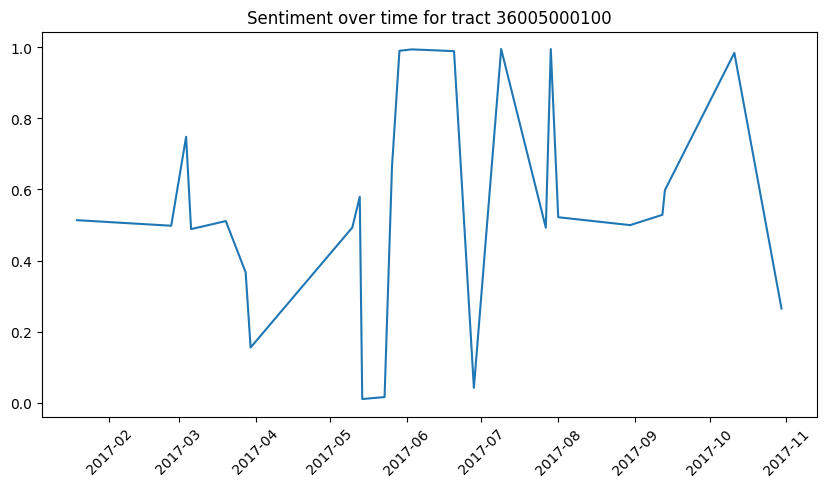

In [15]:
tract = tweet_data["GEOID"].iloc[0]
df = tweet_data[tweet_data["GEOID"] == tract] 

plt.figure(figsize=(10,5))
plt.plot(df["date"], df["mean_sentiment"])
plt.title(f"Sentiment over time for tract {tract}")
plt.xticks(rotation=45)
plt.show()

In [16]:
tract_sentiment = (
    tweet_data
    .groupby("GEOID")["mean_sentiment"]
    .mean()
)

tract_map = tracts.merge(
    tract_sentiment,
    on="GEOID"
)

<Axes: >

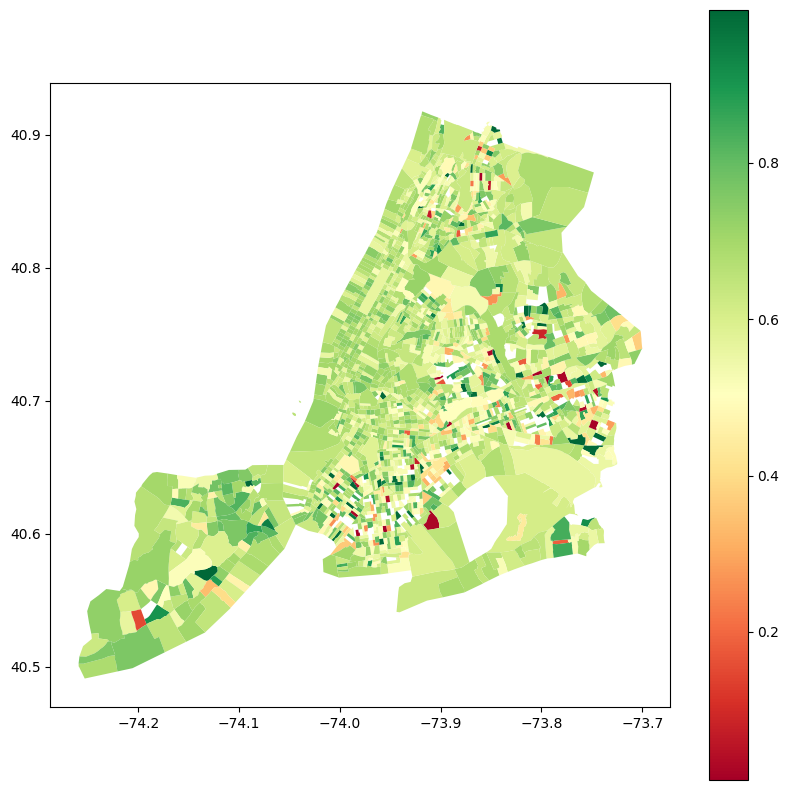

In [17]:
tract_map.plot(
    column="mean_sentiment",
    cmap="RdYlGn",
    legend=True,
    figsize=(10,10)
)

In [19]:
m = folium.Map(
    location=CITY_LOCS[CHOSEN_CITY],
    zoom_start=11,
    tiles="CartoDB positron"
)

folium.Choropleth(
    geo_data=tract_map,
    data=tract_map,
    columns=["GEOID", "mean_sentiment"],
    key_on="feature.properties.GEOID",
    fill_color="RdYlGn",
    legend_name="Average Sentiment"
).add_to(m)

m.save(f"../CityMaps/{CHOSEN_CITY} Sentiment.html")

In [20]:
tweet_data["date"] = pd.to_datetime(tweet_data["date"])

daily_sentiment = (
    tweet_data.groupby(["GEOID","date"])["mean_sentiment"]
    .mean()
    .reset_index()
)

dates = sorted(daily_sentiment["date"].unique())

image_files = []

output_dir = "../Images/Maps/New York"
os.makedirs(output_dir, exist_ok=True)

for i, day in enumerate(dates):
    df_day = daily_sentiment[daily_sentiment["date"] == day]
    
    map_day = tracts.merge(df_day, on="GEOID", how="left")
    
    fig, ax = plt.subplots(1,1, figsize=(12,12))
    map_day.plot(
        column="mean_sentiment",
        cmap="RdYlGn",
        vmin=0, vmax=1,
        legend=True,
        ax=ax
    )
    ax.set_title(f"NYC Sentiment - {day.date()}", fontsize=16)
    ax.axis('off')
    
    # Save image
    img_path = os.path.join(output_dir, f"sentiment_{i:04d}.png")
    plt.savefig(img_path)
    plt.close(fig)
    
    image_files.append(img_path)

In [21]:
import imageio.v3 as iio

images = [iio.imread(f) for f in image_files]

iio.imwrite(f"../Images/Maps/{CHOSEN_CITY}/Sentiment.gif", images, duration=500)

#### Sentiment vs Income

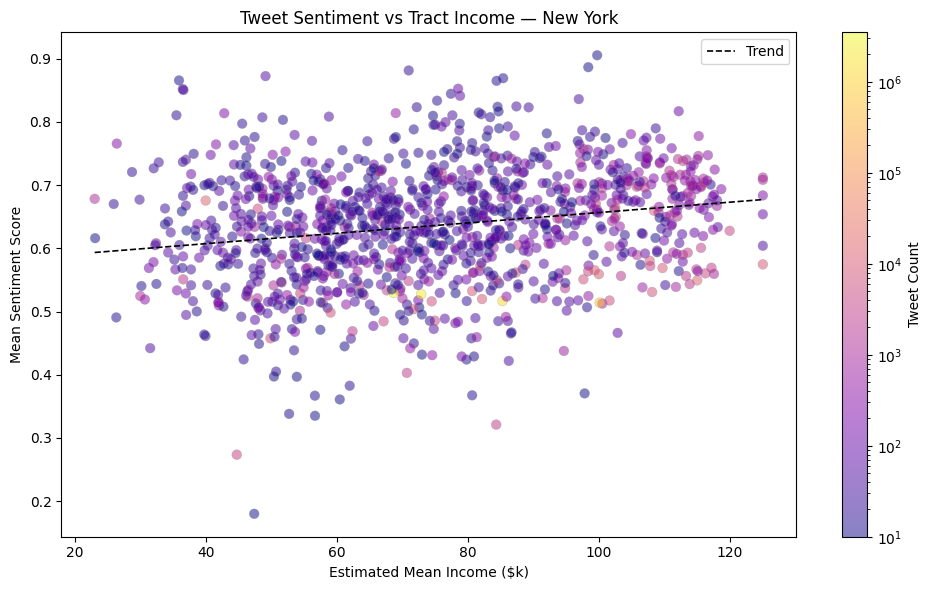

In [ ]:
from Archive_Code.AnalysisTools import process_tweet_folder
import matplotlib as mpl

CHOSEN_CITY = "New York"

# Get sentiment data
sentiment_df = pd.read_pickle(f"../Pickles/{CHOSEN_CITY}.pkl")
sentiment_df = sentiment_df.groupby("GEOID").agg(
    mean_sentiment=("mean_sentiment", "mean"),
    total_tweets=("tweet_count", "sum")
).reset_index()

# Merge income + sentiment on GEOID
sentiment_df["GEOID"] = sentiment_df["GEOID"].str.zfill(11)

merged = sentiment_df.merge(
    gdf[["GEOID", "INCOME_SCORE"]],
    on="GEOID",
    how="inner"
)

# Filter low-sample tracts
merged = merged[merged["total_tweets"] >= 10]

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    merged["INCOME_SCORE"],
    merged["mean_sentiment"],
    s=50,
    alpha=0.5,
    c=merged["total_tweets"],
    cmap="plasma",
    norm=mpl.colors.LogNorm(),
    edgecolors="grey",
    linewidths=0.3
)

z = np.polyfit(merged["INCOME_SCORE"], merged["mean_sentiment"], 1)
p = np.poly1d(z)
x_line = np.linspace(merged["INCOME_SCORE"].min(), merged["INCOME_SCORE"].max(), 200)
ax.plot(x_line, p(x_line), "k--", linewidth=1.2, label="Trend")

plt.colorbar(scatter, ax=ax, label="Tweet Count")
ax.set_xlabel("Estimated Mean Income ($k)")
ax.set_ylabel("Mean Sentiment Score")
ax.set_title("Tweet Sentiment vs Tract Income — New York")
ax.legend()
plt.tight_layout()
plt.savefig("../Figures/Sentiment_vs_Income.png", dpi=300)
plt.show()

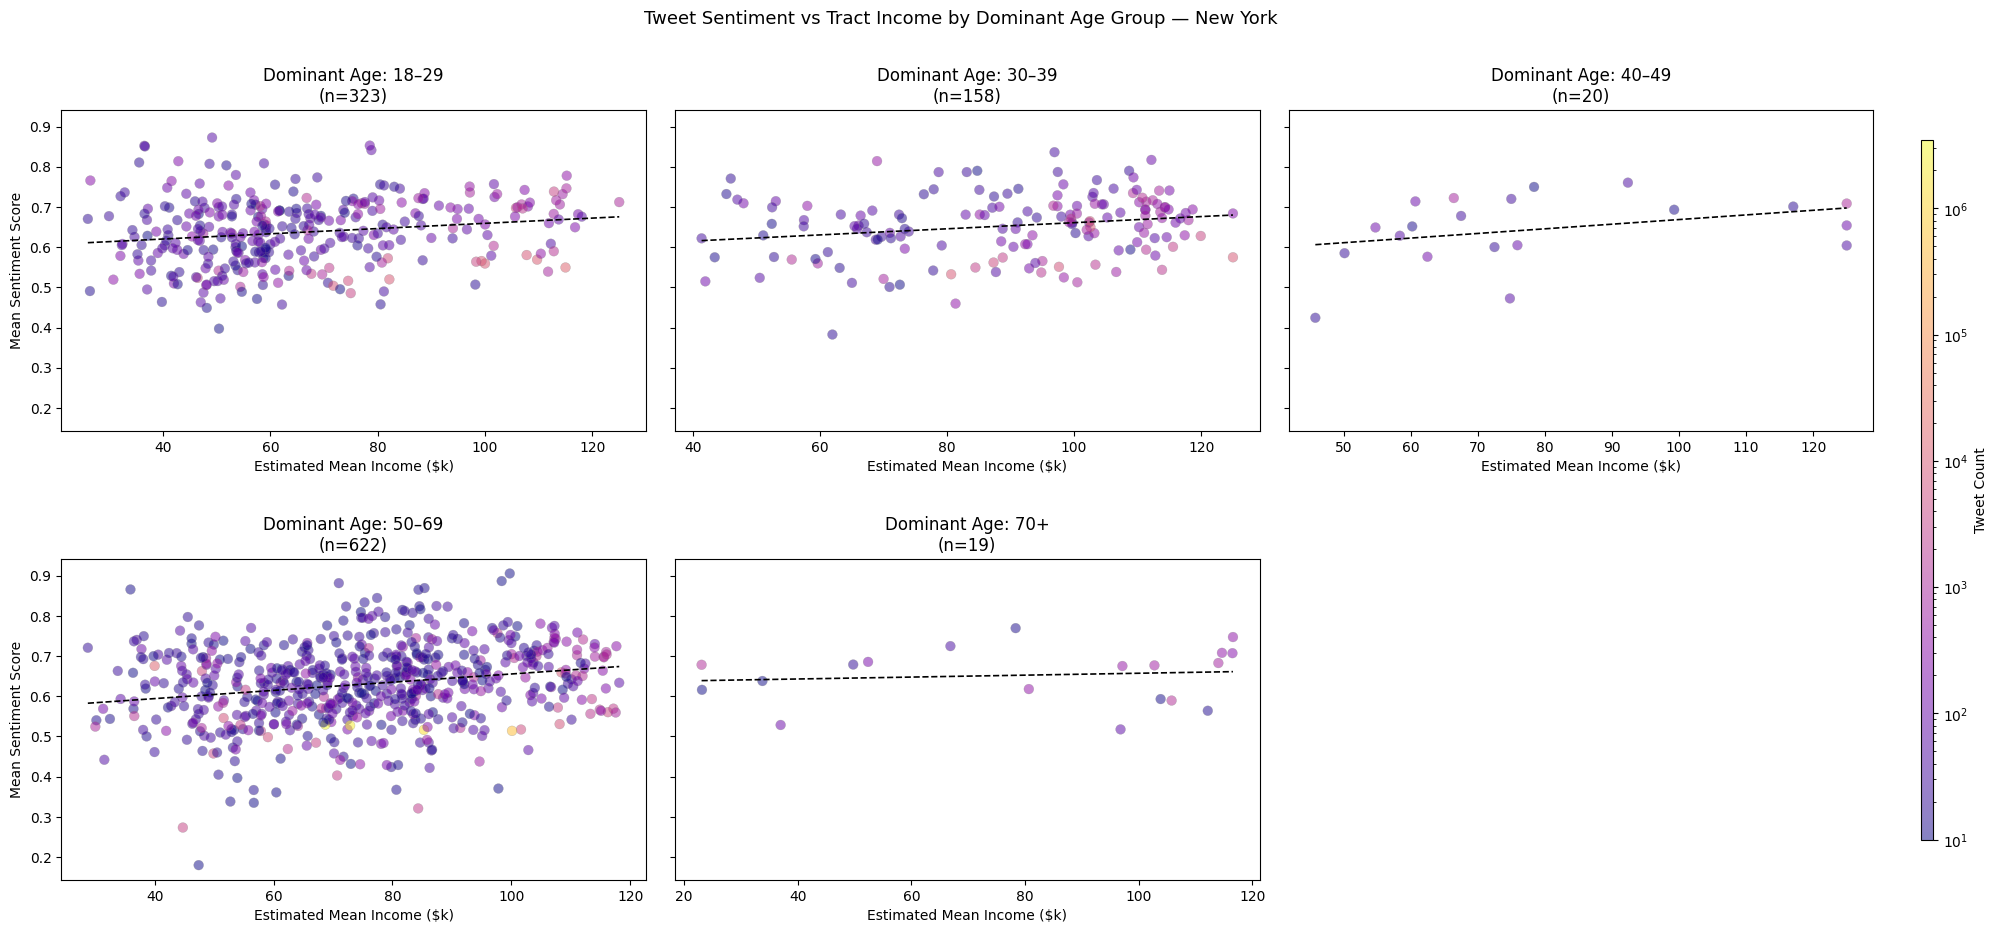

In [32]:
import matplotlib as mpl

CHOSEN_CITY = "New York"

# Get sentiment data
sentiment_df = pd.read_pickle(f"../Pickles/{CHOSEN_CITY}.pkl")
sentiment_df = sentiment_df.groupby("GEOID").agg(
    mean_sentiment=("mean_sentiment", "mean"),
    total_tweets=("tweet_count", "sum")
).reset_index()

sentiment_df["GEOID"] = sentiment_df["GEOID"].str.zfill(11)

# Merge income, sentiment, AND dominant age on GEOID
merged = sentiment_df.merge(
    gdf[["GEOID", "INCOME_SCORE", "dominant_age"]],
    on="GEOID",
    how="inner"
)

merged = merged[merged["total_tweets"] >= 10]

# --- Faceted plot by dominant age group ---
age_groups = ['18–29', '30–39', '40–49', '50–69', '70+']
fig, axes = plt.subplots(2, 3, figsize=(24, 10), sharey=True)
fig.subplots_adjust(right=0.88, wspace=0.05, hspace=0.4)

# Flatten axes and hide the unused 6th slot
axes_flat = axes.flatten()
axes_flat[-1].set_visible(False)

for ax, age in zip(axes_flat, age_groups):
    subset = merged[merged["dominant_age"] == age]

    if subset.empty:
        ax.set_visible(False)
        continue

    scatter = ax.scatter(
        subset["INCOME_SCORE"],
        subset["mean_sentiment"],
        s=50,
        alpha=0.5,
        c=subset["total_tweets"],
        cmap="plasma",
        norm=mpl.colors.LogNorm(
            vmin=merged["total_tweets"].min(),
            vmax=merged["total_tweets"].max()
        ),
        edgecolors="grey",
        linewidths=0.3
    )

    if len(subset) > 1:
        z = np.polyfit(subset["INCOME_SCORE"], subset["mean_sentiment"], 1)
        p = np.poly1d(z)
        x_line = np.linspace(subset["INCOME_SCORE"].min(), subset["INCOME_SCORE"].max(), 200)
        ax.plot(x_line, p(x_line), "k--", linewidth=1.2)

    ax.set_title(f"Dominant Age: {age}\n(n={len(subset)})")
    ax.set_xlabel("Estimated Mean Income ($k)")

axes[0, 0].set_ylabel("Mean Sentiment Score")
axes[1, 0].set_ylabel("Mean Sentiment Score")

cbar_ax = fig.add_axes([0.90, 0.15, 0.005, 0.7])
fig.colorbar(scatter, cax=cbar_ax, label="Tweet Count")

fig.suptitle("Tweet Sentiment vs Tract Income by Dominant Age Group — New York", fontsize=13)
plt.savefig("../Figures/Sentiment_vs_Income_ByAge.png", dpi=300, bbox_inches="tight")
plt.show()

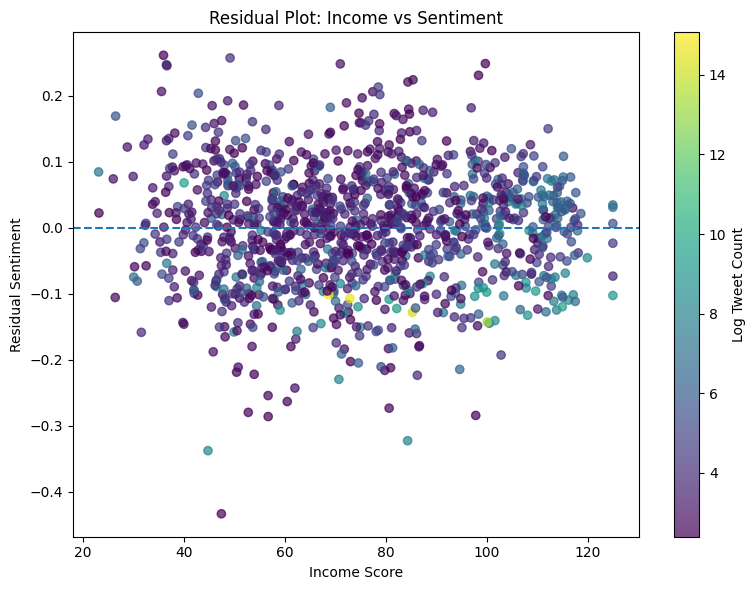

In [52]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Prepare data ----
df = merged.dropna(subset=['INCOME_SCORE', 'mean_sentiment', 'total_tweets']).copy()

x = df['INCOME_SCORE']
y = df['mean_sentiment']

# Regression
coeffs = np.polyfit(x, y, 1)
y_pred = np.polyval(coeffs, x)

# Residuals
df['residual'] = y - y_pred

# Log scale for colour (important)
df['log_tweets'] = np.log1p(df['total_tweets'])

# ---- Plot ----
plt.figure(figsize=(8, 6))

sc = plt.scatter(
    df['INCOME_SCORE'],
    df['residual'],
    c=df['log_tweets'],
    cmap='viridis',
    alpha=0.7
)

# Zero line
plt.axhline(0, linestyle='--')

# Colourbar
cbar = plt.colorbar(sc)
cbar.set_label("Log Tweet Count")

plt.xlabel("Income Score")
plt.ylabel("Residual Sentiment")
plt.title("Residual Plot: Income vs Sentiment")

plt.tight_layout()
plt.show()

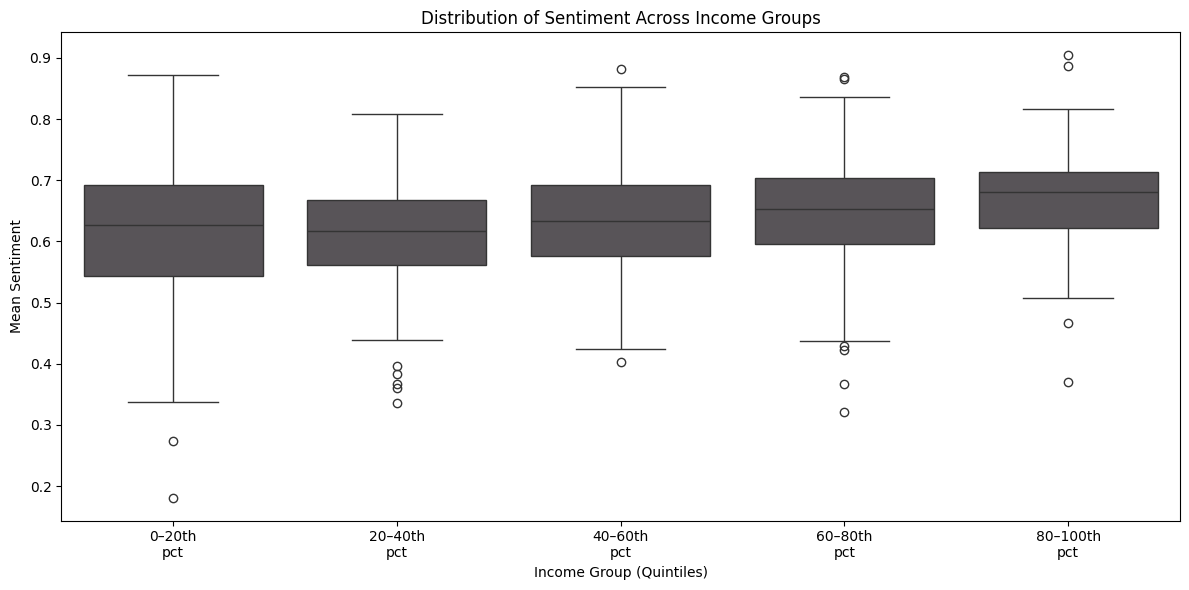

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Prepare data ----
df = merged.dropna(subset=['INCOME_SCORE', 'mean_sentiment']).copy()

# ---- Create income bins (quintiles) ----
df['income_bin'] = pd.qcut(df['INCOME_SCORE'], 5)

# Optional: nicer labels
df['income_bin'] = df['income_bin'].astype(str)
df['income_bin'] = pd.qcut(
    df['INCOME_SCORE'],
    5,
    labels=[
        '0–20th\npct',
        '20–40th\npct',
        '40–60th\npct',
        '60–80th\npct',
        '80–100th\npct'
    ]
)

bins = pd.qcut(df['INCOME_SCORE'], 5)

df['income_bin'] = bins.apply(
    lambda x: f"{int(x.left)}–{int(x.right)}"
)

# ---- Plot ----
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='income_bin',
    y='mean_sentiment',
    color='#595358'
)
plt.xlabel("Income Group (Quintiles)")
plt.ylabel("Mean Sentiment")
plt.title("Distribution of Sentiment Across Income Groups")

plt.tight_layout()
plt.savefig("../Figures/Income_Sentiment_Boxplot.png", dpi=300)
plt.show()

<Axes: xlabel='income_bin', ylabel='mean_sentiment'>

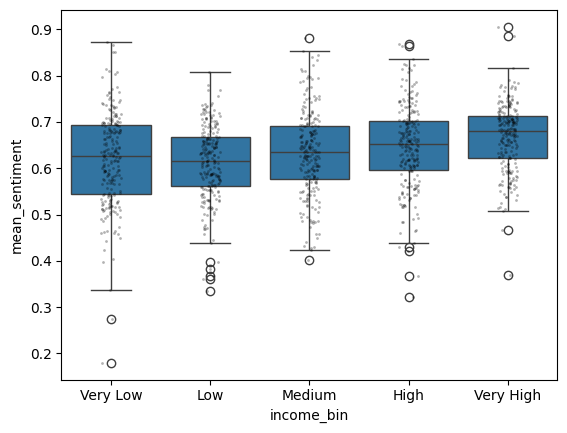

In [56]:
sns.boxplot(data=df, x='income_bin', y='mean_sentiment')
sns.stripplot(
    data=df,
    x='income_bin',
    y='mean_sentiment',
    color='black',
    alpha=0.3,
    size=2
)